# Regression data: exploration and preprocessing

This notebook loads `regression_dataset_40k.csv`, checks its structure and missing values, then builds a leakage-safe preprocessing pipeline for a regression model. Run it from this project folder so the relative CSV path resolves.


In [26]:
from pathlib import Path

import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

DATA_PATH = Path("ble-gspeed.csv")
TARGET = "speed"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Place this notebook in the same folder as the dataset."
    )

df = pd.read_csv(DATA_PATH)
print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
df.head()


Dataset shape: 910,780 rows × 8 columns


,mac,rssi,device,timestamp,user,direction,walk_id,speed
0,DA:4A:C9:76:10:39,-70,a650,1583406563280,6,0,1,1.173019
1,E1:48:EA:70:98:5E,-66,14df,1583406563288,6,0,1,1.173019
2,E1:A3:C1:C7:3F:1A,-64,d884,1583406563293,6,0,1,1.173019
3,E1:A3:C1:C7:3F:1A,-64,14df,1583406563296,6,0,1,1.173019
4,E1:48:EA:70:98:5E,-74,d884,1583406563308,6,0,1,1.173019


## Inspect columns, types, and missing data

The expected data has 40,000 observations, 24 numeric predictors (`Reg_Feat_1` to `Reg_Feat_24`), 6 categorical predictors (`Cat_Feat_1` to `Cat_Feat_6`), and one numeric target. `Reg_Feat_1` is missing in about half of rows, while the other numeric features have much smaller missing rates. The target should not be imputed; rows without a target would be unusable for supervised training.


In [27]:
print("Dataset columns:")
for col in df.columns:
    print(repr(col))
print("\nTotal columns:", len(df.columns))

Dataset columns:
'mac'
'rssi'
'device'
'timestamp'
'user'
'direction'
'walk_id'
'speed'

Total columns: 8


In [28]:
print("Column types:")
display(df.dtypes.value_counts().rename_axis("dtype").to_frame("count"))

missing = df.isna().sum().rename("missing_count").to_frame()
missing["missing_percent"] = (missing["missing_count"] / len(df) * 100).round(2)
display(missing.sort_values("missing_count", ascending=False).head(15))

print("Target summary:")
display(df[TARGET].describe().to_frame())


Column types:


,count
dtype,
int64,5
str,2
float64,1


,missing_count,missing_percent
mac,0,0.0
rssi,0,0.0
device,0,0.0
timestamp,0,0.0
user,0,0.0
direction,0,0.0
walk_id,0,0.0
speed,0,0.0


Target summary:


,speed
count,910780.000000
mean,0.969775
std,0.275221
min,0.429898
25%,0.759424
50%,0.946942
75%,1.115892
max,1.866843


## Before preprocessing: missing values and inconsistent scales

These plots use the raw predictor columns before any imputation or scaling. The missingness chart highlights fields that need imputation, and the boxplots show numeric features on very different scales before standardization.


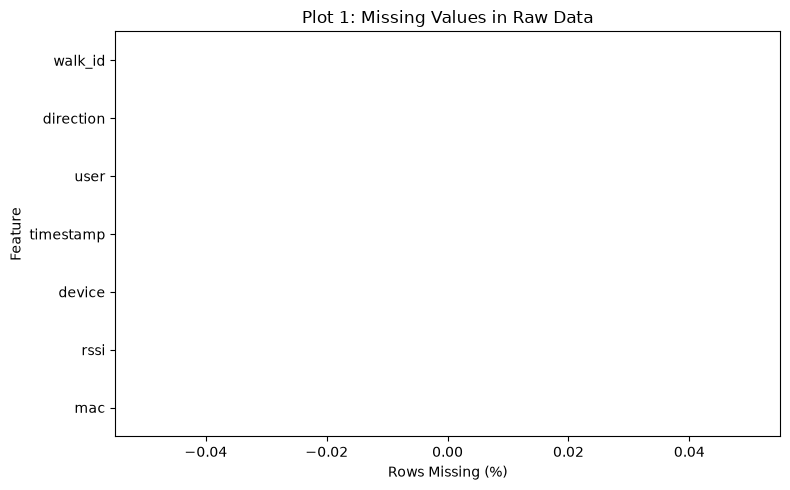

In [30]:
import matplotlib.pyplot as plt

# Exclude the regression target
raw_predictors = df.drop(columns=[TARGET])

# Calculate missing-value percentages
missing_rate = (
    raw_predictors.isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

# Plot missing values
plt.figure(figsize=(8, 5))

missing_rate.head(10).sort_values().plot.barh(
    color="#d97757"
)

plt.title("Plot 1: Missing Values in Raw Data")
plt.xlabel("Rows Missing (%)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

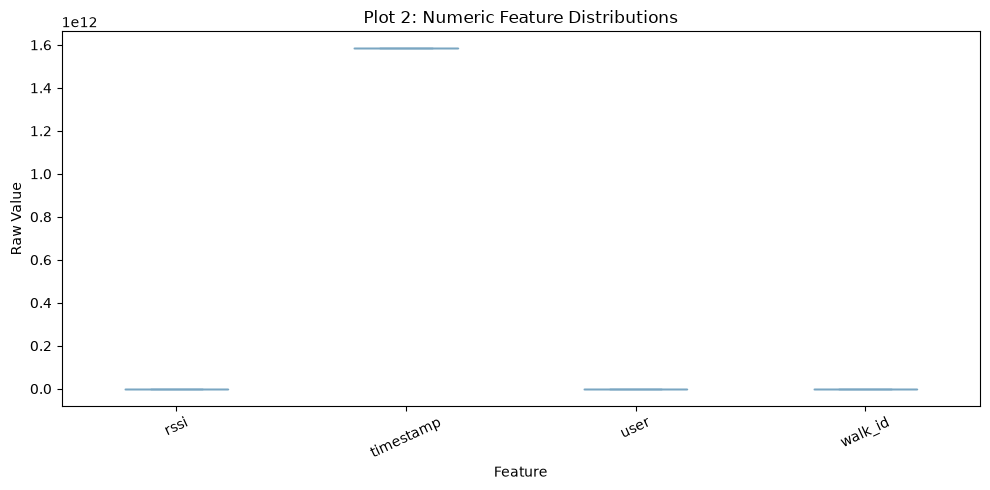

In [32]:
import matplotlib.pyplot as plt

# Select representative numeric predictors available in your dataset
raw_plot_features = [
    col for col in ["rssi", "timestamp", "user", "walk_id"]
    if col in raw_predictors.select_dtypes(include="number").columns
]

# Plot numeric feature distributions
plt.figure(figsize=(10, 5))

raw_predictors[raw_plot_features].plot.box(
    ax=plt.gca(),
    showfliers=False,
    color="#7aa6c2"
)

plt.title("Plot 2: Numeric Feature Distributions")
plt.xlabel("Feature")
plt.ylabel("Raw Value")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [ ]:
# Define predictors and target explicitly so the target cannot enter the preprocessing pipeline.
X = df.drop(columns=TARGET)
y = df[TARGET]

numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print(f"Numeric predictors ({len(numeric_features)}): {numeric_features}")
print(f"Categorical predictors ({len(categorical_features)}): {categorical_features}")
assert len(numeric_features) == 24, "Review the numeric columns: 24 were expected."
assert len(categorical_features) == 6, "Review the categorical columns: 6 were expected."
assert y.notna().all(), "Target has missing values; decide how to handle them before training."



Numeric predictors (24): ['Reg_Feat_1', 'Reg_Feat_2', 'Reg_Feat_3', 'Reg_Feat_4', 'Reg_Feat_5', 'Reg_Feat_6', 'Reg_Feat_7', 'Reg_Feat_8', 'Reg_Feat_9', 'Reg_Feat_10', 'Reg_Feat_11', 'Reg_Feat_12', 'Reg_Feat_13', 'Reg_Feat_14', 'Reg_Feat_15', 'Reg_Feat_16', 'Reg_Feat_17', 'Reg_Feat_18', 'Reg_Feat_19', 'Reg_Feat_20', 'Reg_Feat_21', 'Reg_Feat_22', 'Reg_Feat_23', 'Reg_Feat_24']
Categorical predictors (6): ['Cat_Feat_1', 'Cat_Feat_2', 'Cat_Feat_3', 'Cat_Feat_4', 'Cat_Feat_5', 'Cat_Feat_6']


/var/folders/g9/ldd8rzbd60x38qjcxvs3__4h0000gn/T/ipykernel_18623/3896945619.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


## Split first, then fit preprocessing on training data

Median imputation is robust to the numeric features' large values and outliers. A missingness indicator is added for numeric columns with missing values, so the model can learn from the unusually high missing rate in `Reg_Feat_1`. Categorical missing values, if any appear, are filled with the most frequent training value; categories are one-hot encoded, with unseen validation/test categories safely ignored.

The split happens before fitting any imputer, scaler, or encoder. This prevents validation data from influencing preprocessing statistics.


In [33]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Define target and predictors
TARGET = "speed"
X = df.drop(columns=[TARGET])
y = df[TARGET]

# Treat identifiers as categorical features
categorical_columns = ["mac", "device", "user", "walk_id", "direction"]

categorical_features = [
    col for col in categorical_columns if col in X.columns
]

# Identify remaining numeric predictors
numeric_features = [
    col for col in X.select_dtypes(include="number").columns
    if col not in categorical_features
]

print(f"Numeric predictors ({len(numeric_features)}): {numeric_features}")
print(f"Categorical predictors ({len(categorical_features)}): {categorical_features}")

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Numeric preprocessing pipeline
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
])

# Categorical preprocessing pipeline
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

# Combine preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

# Fit on training data and transform both datasets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Display results
print("\nTraining predictors after preprocessing:", X_train_processed.shape)
print("Test predictors after preprocessing:", X_test_processed.shape)
print("Training target:", y_train.shape)
print("Test target:", y_test.shape)

Numeric predictors (2): ['rssi', 'timestamp']
Categorical predictors (5): ['mac', 'device', 'user', 'walk_id', 'direction']

Training predictors after preprocessing: (728624, 422)
Test predictors after preprocessing: (182156, 422)
Training target: (728624,)
Test target: (182156,)


## After preprocessing: imputed and standardized numeric features

The fitted numeric pipeline fills missing values with training medians, adds missingness indicators, and standardizes feature values. The plots compare the same numeric columns before and after those steps. This improves input consistency for scale-sensitive models; it does not guarantee better predictive accuracy by itself.


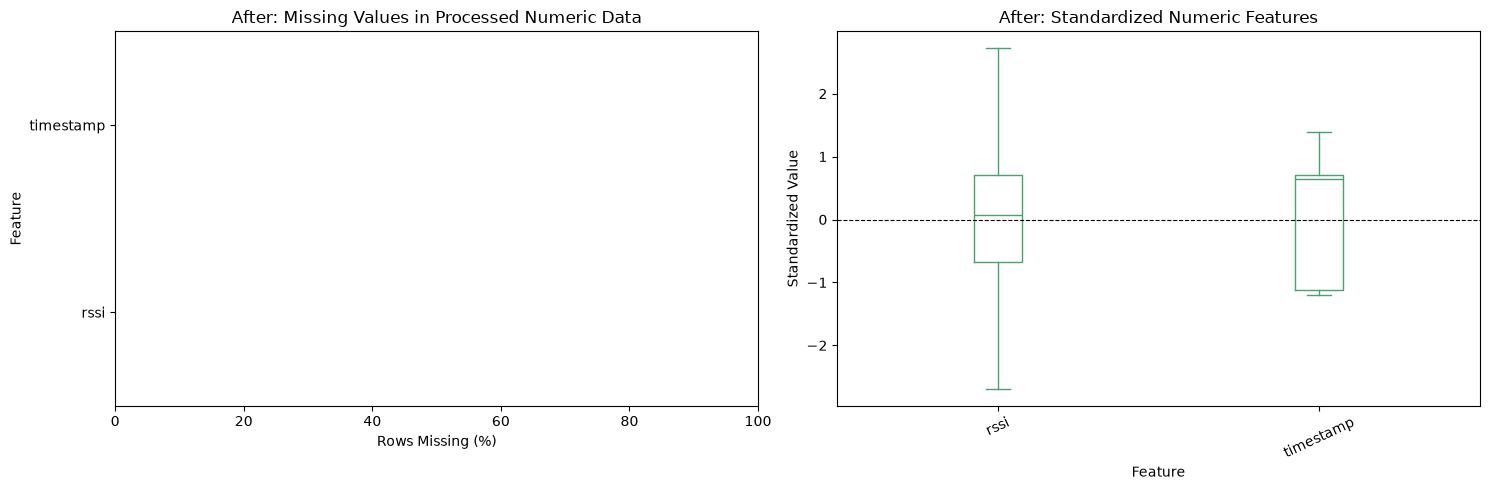

Missing cells in processed numeric features: 0

Feature means after scaling (approximately 0):


,mean
rssi,0.0
timestamp,0.0


In [34]:
# Transform numeric training columns using the fitted preprocessing pipeline
X_train_numeric_processed = preprocessor.named_transformers_["numeric"].transform(
    X_train[numeric_features]
)

# Build names for numeric features and missing-value indicators
processed_numeric_names = numeric_features + [
    f"missingindicator_{name}"
    for name in numeric_features
    if X_train[name].isna().any()
]

# Create a DataFrame of processed numeric features
processed_numeric = pd.DataFrame(
    X_train_numeric_processed,
    columns=processed_numeric_names,
    index=X_train.index
)

# Create two plots
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Missing values after preprocessing
remaining_missing = processed_numeric.isna().mean().mul(100)

remaining_missing.head(10).sort_values().plot.barh(
    ax=axes[0],
    color="#4c9f70"
)

axes[0].set(
    title="After: Missing Values in Processed Numeric Data",
    xlabel="Rows Missing (%)",
    ylabel="Feature"
)
axes[0].set_xlim(0, 100)

# Plot 2: Standardized numeric feature distributions
scaled_plot_features = [
    name for name in numeric_features
    if name in processed_numeric.columns
]

if scaled_plot_features:
    processed_numeric[scaled_plot_features].plot.box(
        ax=axes[1],
        showfliers=False,
        color="#4c9f70"
    )

    axes[1].axhline(
        0,
        color="black",
        linewidth=0.8,
        linestyle="--"
    )

    axes[1].set(
        title="After: Standardized Numeric Features",
        xlabel="Feature",
        ylabel="Standardized Value"
    )

    axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

# Report missing values and feature means
print(
    "Missing cells in processed numeric features:",
    int(processed_numeric.isna().sum().sum())
)

print("\nFeature means after scaling (approximately 0):")

display(
    processed_numeric[numeric_features]
    .mean()
    .round(2)
    .to_frame("mean")
)

## Use with a regression estimator

Keep the fitted `preprocessor` together with a regression estimator in a single pipeline when training and evaluating models. This makes cross-validation and future predictions apply the same transformations consistently.


In [20]:
# Example template (uncomment after choosing a regression model):
# from sklearn.ensemble import RandomForestRegressor
# from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
#
# model = Pipeline(steps=[
#     ("preprocessing", preprocessor),
#     ("regressor", RandomForestRegressor(random_state=42)),
# ])
# model.fit(X_train, y_train)
# predictions = model.predict(X_test)
# print("MAE:", mean_absolute_error(y_test, predictions))
# print("RMSE:", mean_squared_error(y_test, predictions) ** 0.5)
# print("R²:", r2_score(y_test, predictions))
